In [42]:
# Import necessary libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind

gender                                    female
race/ethnicity                           group B
parental level of education    bachelor's degree
lunch                                   standard
test preparation course                     none
math score                                    72
reading score                                 72
writing score                                 74
Name: 0, dtype: object

gender                               female
race/ethnicity                      group C
parental level of education    some college
lunch                              standard
test preparation course           completed
math score                               69
reading score                            90
writing score                            88
Name: 1, dtype: object

gender                                  female
race/ethnicity                         group B
parental level of education    master's degree
lunch                                 standard
test preparation cou

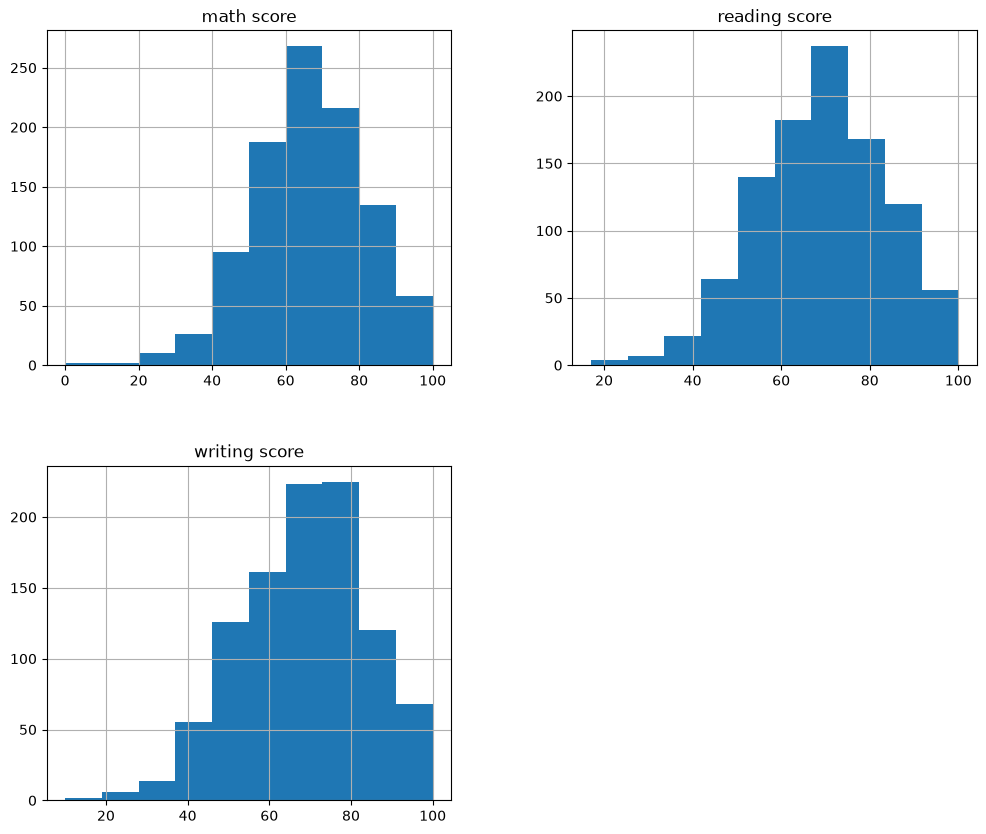

gender
str

race/ethnicity
str

parental level of education
str

lunch
str

test preparation course
str

math score
int64

reading score
int64

writing score
int64

Numeric columns: Index(['math score', 'reading score', 'writing score'], dtype='str')
Categorical columns: Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course'],
      dtype='str')


C:\Users\jppea\AppData\Local\Temp\ipykernel_9704\3027112974.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = dataset.select_dtypes(include=['object']).columns


In [43]:
#Q2A

# Load and display the first 10 rows of the student performance dataset
dataset = pd.read_csv('datasets/Q2_Student_Performance_Dataset.csv')
for i in range(0,10):
    print(f'{dataset.iloc[i,:]}\n')

# graph dataset distrubtion
dataset.hist(figsize=(12,10))
plt.show()

# Display the column names of the dataset
for i in range(len(dataset.columns)):
    print(f'{dataset.columns[i]}\n{dataset[dataset.columns[i]].dtype}\n')

# Identify numeric and categorical columns in the dataset
numeric_columns = dataset.select_dtypes(include=['number']).columns
categorical_columns = dataset.select_dtypes(include=['object']).columns
print(f'Numeric columns: {numeric_columns}')
print(f'Categorical columns: {categorical_columns}')


In [44]:
#Q2B

# Check for missing values in the dataset
if dataset.isnull().any().any():
    print("There are missing values in the dataset.")
else:
    print("There are no missing values in the dataset.")

# Check for duplicate rows in the dataset
if dataset.duplicated().any():
    print("There are duplicate rows in the dataset.")
else:
    print("There are no duplicate rows in the dataset.")

# Checking for inconsistent values in the categorical columns
column_values = {col: dataset[col].unique() for col in dataset.columns}
for col, values in column_values.items():
    print(f"Column {col} has values: {values}")

print("Finished checking for inconsistent values in the categorical columns.\n"
      "No inconsistent values found.")

for i in range(len(categorical_columns)):
    print(f'{categorical_columns[i]} has values: {column_values[categorical_columns[i]]}'
          f' with datatype: {dataset[categorical_columns[i]].dtype}')

# Calculate IQR bounds for each score column
math_q25, math_q75 = np.percentile(dataset['math score'], 25), np.percentile(dataset['math score'], 75)
math_iqr = math_q75 - math_q25
math_lower, math_upper = math_q25 - 1.5 * math_iqr, math_q75 + 1.5 * math_iqr

reading_q25, reading_q75 = np.percentile(dataset['reading score'], 25), np.percentile(dataset['reading score'], 75)
reading_iqr = reading_q75 - reading_q25
reading_lower, reading_upper = reading_q25 - 1.5 * reading_iqr, reading_q75 + 1.5 * reading_iqr

writing_q25, writing_q75 = np.percentile(dataset['writing score'], 25), np.percentile(dataset['writing score'], 75)
writing_iqr = writing_q75 - writing_q25
writing_lower, writing_upper = writing_q25 - 1.5 * writing_iqr, writing_q75 + 1.5 * writing_iqr

# Identify outliers using boolean masks
is_math_outlier = (dataset['math score'] < math_lower) | (dataset['math score'] > math_upper)
is_reading_outlier = (dataset['reading score'] < reading_lower) | (dataset['reading score'] > reading_upper)
is_writing_outlier = (dataset['writing score'] < writing_lower) | (dataset['writing score'] > writing_upper)

# Count how many outlier conditions are met per row
outlier_count = is_math_outlier.astype(int) + is_reading_outlier.astype(int) + is_writing_outlier.astype(int)

# Filter out rows with 2 or more outliers
rows_to_remove = outlier_count >= 2
removed_columns = rows_to_remove.sum()
dataset = dataset[~rows_to_remove].reset_index(drop=True)

print(f'Total removed rows: {removed_columns} because they had 2 or more outliers in the scores columns.')

There are no missing values in the dataset.
There are no duplicate rows in the dataset.
Column gender has values: <StringArray>
['female', 'male']
Length: 2, dtype: str
Column race/ethnicity has values: <StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str
Column parental level of education has values: <StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str
Column lunch has values: <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
Column test preparation course has values: <StringArray>
['none', 'completed']
Length: 2, dtype: str
Column math score has values: [ 72  69  90  47  76  71  88  40  64  38  58  65  78  50  18  46  54  66
  44  74  73  67  70  62  63  56  97  81  75  57  55  53  59  82  77  33
  52   0  79  39  45  60  61  41  49  30  80  42  27  43  68  85  98  87
  51  99  84  91  83  89  22 100  96  94  48  35

In [45]:
# Q2C

# calculating summary statistics for the scores columns
math_summary = dataset['math score'].describe()
reading_summary = dataset['reading score'].describe()
writing_summary = dataset['writing score'].describe()

print("Math Summary Statistics:\n", math_summary)
print("Reading Summary Statistics:\n", reading_summary)
print("Writing Summary Statistics:\n", writing_summary)

print('Reading mean is better than Writing mean, which is better than Math mean.')

math_no_prep = dataset[dataset['test preparation course'] == 'none']['math score'].describe()
reading_no_prep = dataset[dataset['test preparation course'] == 'none']['reading score'].describe()
writing_no_prep = dataset[dataset['test preparation course'] == 'none']['writing score'].describe()
math_prep = dataset[dataset['test preparation course'] == 'completed']['math score'].describe()
reading_prep = dataset[dataset['test preparation course'] == 'completed']['reading score'].describe()
writing_prep = dataset[dataset['test preparation course'] == 'completed']['writing score'].describe()
if math_prep['mean'] > math_no_prep['mean']:
    print("Math scores improved after test preparation.")
else:
    print("Math scores did not improve after test preparation.")

if reading_prep['mean'] > reading_no_prep['mean']:
    print("Reading scores improved after test preparation.")
else:
    print("Reading scores did not improve after test preparation.")

if writing_prep['mean'] > writing_no_prep['mean']:
    print("Writing scores improved after test preparation.")
else:
    print("Writing scores did not improve after test preparation.")

# seeing if reading and writing scores are correlated
correlation = dataset['reading score'].corr(dataset['writing score'])
print(f'The correlation between reading and writing scores is: {correlation:.2f}')
if correlation > 0:
    print("Reading and writing scores are positively correlated.")
elif correlation < 0:
    print("Reading and writing scores are negatively correlated.")

# interesting patterns in the dataset
print("Students who completed the test preparation course tend to have higher average scores across all subjects compared to those who did not complete the course.")
print("There is a strong positive correlation between reading and writing scores, indicating that students who perform well in one subject are likely to perform well in the other.")
print("The distribution of scores shows that most students score in the middle range, with fewer students achieving very high or very low scores, suggesting a normal distribution of performance")

Math Summary Statistics:
 count    995.000000
mean      66.324623
std       14.803751
min       18.000000
25%       57.000000
50%       66.000000
75%       77.000000
max      100.000000
Name: math score, dtype: float64
Reading Summary Statistics:
 count    995.000000
mean      69.402010
std       14.259072
min       28.000000
25%       59.500000
50%       70.000000
75%       79.500000
max      100.000000
Name: reading score, dtype: float64
Writing Summary Statistics:
 count    995.000000
mean      68.306533
std       14.804953
min       27.000000
25%       58.000000
50%       69.000000
75%       79.000000
max      100.000000
Name: writing score, dtype: float64
Reading mean is better than Writing mean, which is better than Math mean.
Math scores improved after test preparation.
Reading scores improved after test preparation.
Writing scores improved after test preparation.
The correlation between reading and writing scores is: 0.95
Reading and writing scores are positively correlated.
St

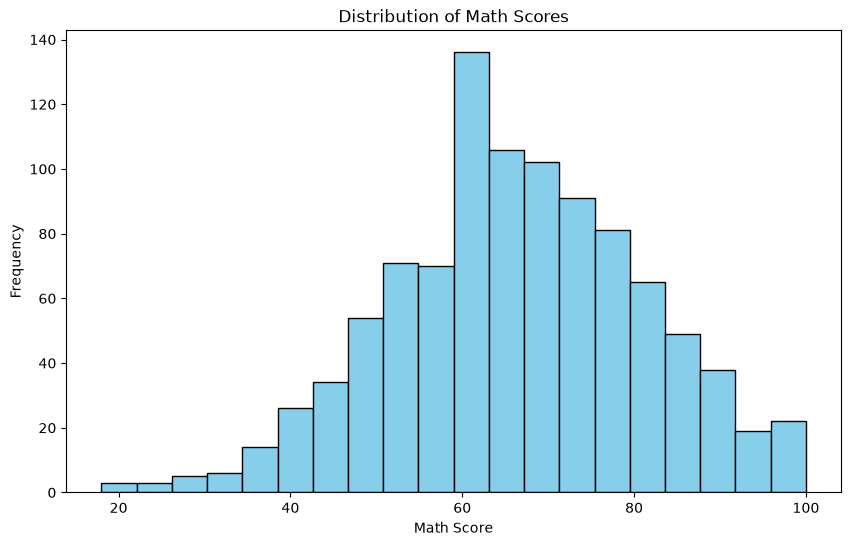

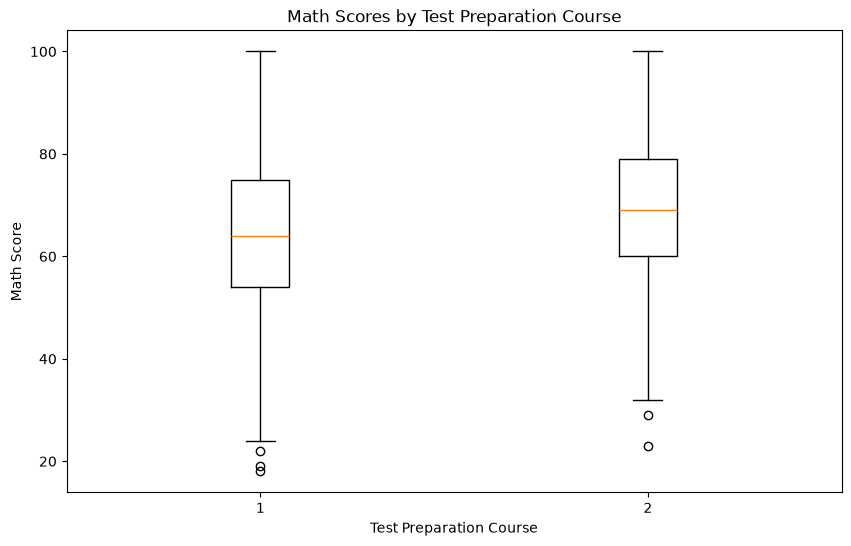

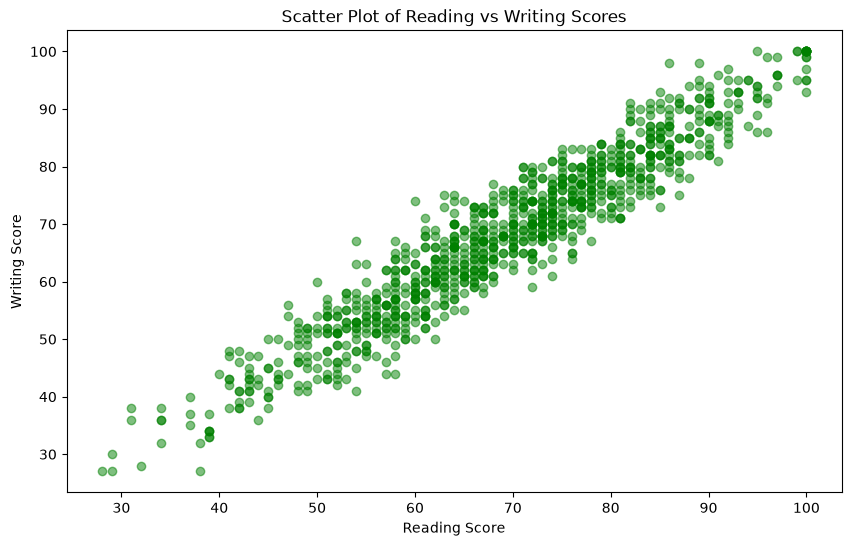

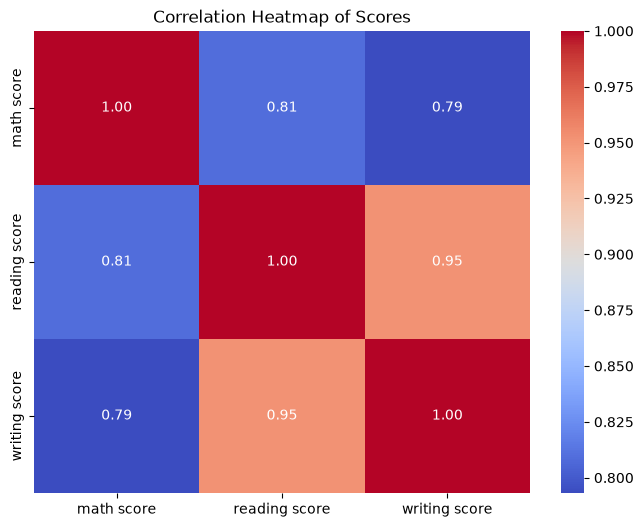

In [46]:
# Q2D

# distribution plot for math score
plt.figure(figsize=(10, 6))
plt.hist(dataset['math score'], bins=20, color='skyblue', edgecolor='black')
plt.xlabel('Math Score')
plt.ylabel('Frequency')
plt.title('Distribution of Math Scores')
plt.show()

# boxplot for math score by test preparation course
plt.figure(figsize=(10, 6))
plt.boxplot([dataset[dataset['test preparation course'] == 'none']['math score'], dataset[dataset['test preparation course'] == 'completed']['math score']], label=['No Preparation', 'Completed Preparation'])
plt.xlabel('Test Preparation Course')
plt.ylabel('Math Score')
plt.title('Math Scores by Test Preparation Course')
plt.show()

# scatter plot for reading score vs writing score
plt.figure(figsize=(10, 6))
plt.scatter(dataset['reading score'], dataset['writing score'], color='green', alpha=0.5)
plt.xlabel('Reading Score')
plt.ylabel('Writing Score')
plt.title('Scatter Plot of Reading vs Writing Scores')
plt.show()

# correlation heatmap for scores
plt.figure(figsize=(8, 6))
sns.heatmap(dataset[['math score', 'reading score', 'writing score']].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Scores')
plt.show()


In [47]:
#Q2E

# calculating stats for math scores
mean_math = dataset['math score'].mean()
median_math = dataset['math score'].median()
variance_math = dataset['math score'].var()
std_math = dataset['math score'].std()
quartiles_math = dataset['math score'].quantile([0.25, 0.5, 0.75])

print("H0: There is no significant difference in math scores between students who completed the test preparation course and those who did not.")
print("H1: There is a significant difference in math scores between students who completed the test preparation course and those who did not.")

print("Using T test to compare the means of the two groups.")
alpha = 0.05
pvalue = ttest_ind(dataset[dataset['test preparation course'] == 'none']['math score'], dataset[dataset['test preparation course'] == 'completed']['math score']).pvalue
if pvalue < alpha:
    print(f"Reject H0: p-value = {pvalue:.4f}. There is a significant difference in math scores between the two groups.")

print("Students who completed the test preparation course have a higher mean math score compared to those who did not complete the course, indicating that the test preparation course has a positive effect on math performance.")

H0: There is no significant difference in math scores between students who completed the test preparation course and those who did not.
H1: There is a significant difference in math scores between students who completed the test preparation course and those who did not.
Using T test to compare the means of the two groups.
Reject H0: p-value = 0.0000. There is a significant difference in math scores between the two groups.
Students who completed the test preparation course have a higher mean math score compared to those who did not complete the course, indicating that the test preparation course has a positive effect on math performance.
